In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [2]:
df = pd.read_csv("../data/student_career_success_dataset.csv")

In [3]:
df.head()

,Student_ID,Age,Gender,University_Year,Major,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Academic_Performance,Programming_Skill,...,Teamwork,Problem_Solving,English_Proficiency,Interview_Score,Employability_Score,Placement_Status,Company_Tier,Career_Field,Placement_Mode,Starting_Salary_USD
0,ST000001,22,Male,Sophomore,Computer Science,86,21,3.28,Good,9,...,7,8,Advanced,72,231.70,Placed,Tier 1,Backend Developer,Campus Placement,72082
1,ST000002,20,Female,Freshman,Computer Science,64,18,2.53,Poor,6,...,6,5,Basic,59,157.45,Not Placed,No Company,Not Placed,Not Applicable,0
2,ST000003,23,Male,Senior,Information Technology,75,19,2.83,Average,8,...,8,7,Advanced,76,203.45,Placed,Tier 1,IT Support Engineer,Campus Placement,94898
3,ST000004,23,Female,Senior,Information Technology,80,19,2.80,Average,5,...,6,6,Intermediate,67,171.50,Not Placed,No Company,Not Placed,Not Applicable,0
4,ST000005,23,Female,Senior,Software Engineering,73,19,2.93,Average,9,...,8,9,Advanced,82,225.45,Placed,Tier 1,Software Engineer,Internship Conversion,85256


In [4]:
df.shape

(50000, 29)

In [5]:
df.columns

Index(['Student_ID', 'Age', 'Gender', 'University_Year', 'Major',
       'Attendance_Percentage', 'Study_Hours_Per_Week', 'CGPA',
       'Academic_Performance', 'Programming_Skill', 'Projects_Completed',
       'Certifications', 'Hackathons', 'GitHub_Profile', 'Internships',
       'Leadership_Experience', 'LinkedIn_Profile', 'Resume_Score',
       'Communication_Skills', 'Teamwork', 'Problem_Solving',
       'English_Proficiency', 'Interview_Score', 'Employability_Score',
       'Placement_Status', 'Company_Tier', 'Career_Field', 'Placement_Mode',
       'Starting_Salary_USD'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             50000 non-null  str    
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  str    
 3   University_Year        50000 non-null  str    
 4   Major                  50000 non-null  str    
 5   Attendance_Percentage  50000 non-null  int64  
 6   Study_Hours_Per_Week   50000 non-null  int64  
 7   CGPA                   50000 non-null  float64
 8   Academic_Performance   50000 non-null  str    
 9   Programming_Skill      50000 non-null  int64  
 10  Projects_Completed     50000 non-null  int64  
 11  Certifications         50000 non-null  int64  
 12  Hackathons             50000 non-null  int64  
 13  GitHub_Profile         50000 non-null  str    
 14  Internships            50000 non-null  int64  
 15  Leadership_Ex

In [7]:
df.describe()

,Age,Attendance_Percentage,Study_Hours_Per_Week,CGPA,Programming_Skill,Projects_Completed,Certifications,Hackathons,Internships,Resume_Score,Communication_Skills,Teamwork,Problem_Solving,Interview_Score,Employability_Score,Starting_Salary_USD
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,21.262900,81.409640,21.52816,3.106043,7.137160,8.620560,1.715660,3.093940,4.048880,96.045740,8.435780,7.006200,7.175060,77.515400,213.991394,68988.167480
std,2.041163,9.709519,6.97481,0.290351,1.507194,2.505408,1.368301,1.660774,1.005719,7.331565,1.387543,1.606802,1.674428,12.579382,26.824224,38480.607679
min,18.000000,50.000000,5.00000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,44.000000,3.000000,2.000000,1.000000,17.000000,82.300000,0.000000
25%,20.000000,75.000000,17.00000,2.910000,6.000000,7.000000,1.000000,2.000000,3.000000,95.000000,7.000000,6.000000,6.000000,70.000000,197.350000,65229.250000
50%,21.000000,82.000000,21.00000,3.110000,7.000000,9.000000,2.000000,3.000000,4.000000,100.000000,9.000000,7.000000,7.000000,78.000000,217.250000,83044.500000
75%,22.000000,88.000000,26.00000,3.310000,8.000000,10.000000,3.000000,4.000000,5.000000,100.000000,10.000000,8.000000,8.000000,87.000000,233.600000,96486.250000
max,30.000000,100.000000,45.00000,4.000000,10.000000,15.000000,8.000000,10.000000,5.000000,100.000000,10.000000,10.000000,10.000000,100.000000,279.050000,110000.000000


In [8]:
df.isnull().sum().sum()

np.int64(0)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.shape

(50000, 29)

In [11]:
df["Career_Field"].value_counts()

Career_Field
Not Placed                   10960
Software Engineer             6544
Data Scientist                3845
AI Engineer                   3792
Backend Developer             3352
DevOps Engineer               3214
Full Stack Developer          3198
Data Analyst                  2749
Machine Learning Engineer     2152
IT Support Engineer           1745
Cloud Engineer                1717
SOC Analyst                   1346
Cybersecurity Analyst         1318
Penetration Tester            1298
Business Analyst              1236
Automation Engineer            777
Embedded Systems Engineer      757
Name: count, dtype: int64

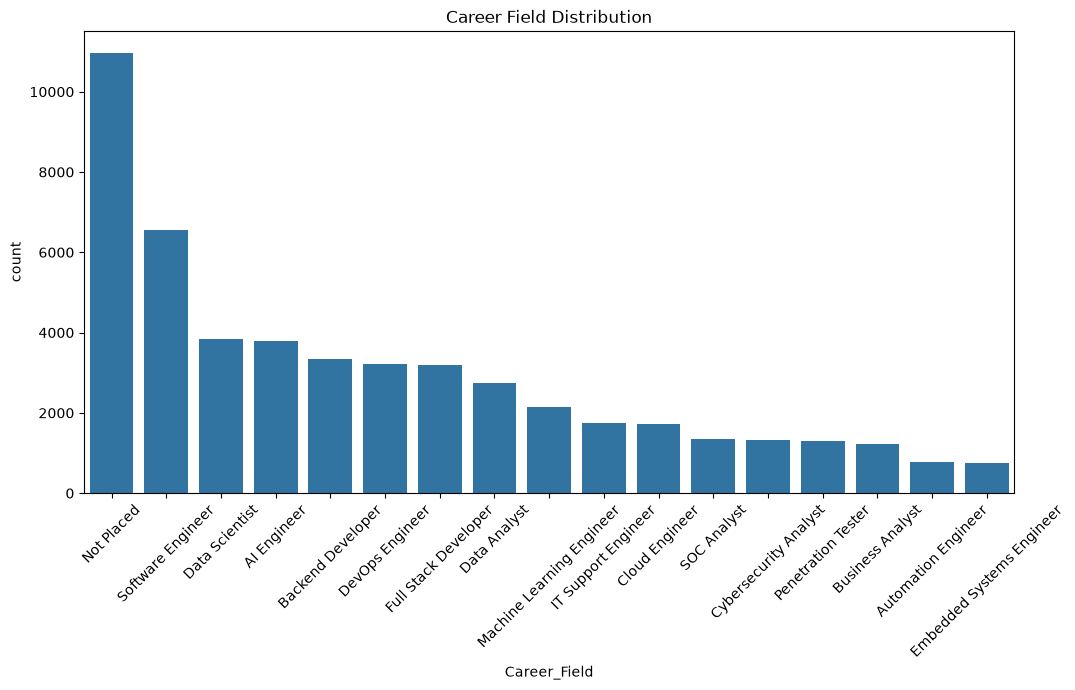

In [12]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Career_Field",
    order=df["Career_Field"].value_counts().index
)

plt.xticks(rotation=45)
plt.title("Career Field Distribution")
plt.show()

In [13]:
df = df[df["Career_Field"] != "Not Placed"].copy()

In [14]:
df["Career_Field"].value_counts()

Career_Field
Software Engineer            6544
Data Scientist               3845
AI Engineer                  3792
Backend Developer            3352
DevOps Engineer              3214
Full Stack Developer         3198
Data Analyst                 2749
Machine Learning Engineer    2152
IT Support Engineer          1745
Cloud Engineer               1717
SOC Analyst                  1346
Cybersecurity Analyst        1318
Penetration Tester           1298
Business Analyst             1236
Automation Engineer           777
Embedded Systems Engineer     757
Name: count, dtype: int64

In [15]:
drop_columns = [
    "Student_ID",
    "Placement_Status",
    "Company_Tier",
    "Placement_Mode",
    "Starting_Salary_USD"
]

df = df.drop(columns=drop_columns)

In [16]:
df.columns

Index(['Age', 'Gender', 'University_Year', 'Major', 'Attendance_Percentage',
       'Study_Hours_Per_Week', 'CGPA', 'Academic_Performance',
       'Programming_Skill', 'Projects_Completed', 'Certifications',
       'Hackathons', 'GitHub_Profile', 'Internships', 'Leadership_Experience',
       'LinkedIn_Profile', 'Resume_Score', 'Communication_Skills', 'Teamwork',
       'Problem_Solving', 'English_Proficiency', 'Interview_Score',
       'Employability_Score', 'Career_Field'],
      dtype='str')

In [17]:
target = "Career_Field"

In [18]:
X = df.drop(columns=[target])
y = df[target]

In [19]:
X.shape

(39040, 23)

In [20]:
y.shape

(39040,)

In [21]:
y.unique()

<StringArray>
[        'Backend Developer',       'IT Support Engineer',
         'Software Engineer',               'AI Engineer',
      'Full Stack Developer',            'Data Scientist',
           'DevOps Engineer',     'Cybersecurity Analyst',
        'Penetration Tester',          'Business Analyst',
               'SOC Analyst',            'Cloud Engineer',
 'Machine Learning Engineer',       'Automation Engineer',
              'Data Analyst', 'Embedded Systems Engineer']
Length: 16, dtype: str

In [23]:
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Attendance_Percentage', 'Study_Hours_Per_Week', 'CGPA', 'Programming_Skill', 'Projects_Completed', 'Certifications', 'Hackathons', 'Internships', 'Resume_Score', 'Communication_Skills', 'Teamwork', 'Problem_Solving', 'Interview_Score', 'Employability_Score']

Categorical Features:
['Gender', 'University_Year', 'Major', 'Academic_Performance', 'GitHub_Profile', 'Leadership_Experience', 'LinkedIn_Profile', 'English_Proficiency']


In [24]:
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [26]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (31232, 23)
Testing data: (7808, 23)


In [27]:
decision_tree = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42,
                max_depth=10
            )
        )
    ]
)

In [28]:
decision_tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](16,)","['AI Engineer','Automation Engineer','Backend Developer',..., 'Penetration Tester','SOC Analyst','Software Engineer']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Age','Gender','University_Year',...,'English_Proficiency', 'Interview_Score','Employability_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransform

In [29]:
y_pred_dt = decision_tree.predict(X_test)

In [30]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.3958760245901639


In [31]:
print(
    classification_report(
        y_test,
        y_pred_dt
    )
)

                           precision    recall  f1-score   support

              AI Engineer       0.32      0.11      0.17       758
      Automation Engineer       0.56      0.32      0.40       155
        Backend Developer       0.37      0.45      0.41       670
         Business Analyst       0.51      0.77      0.61       247
           Cloud Engineer       0.54      0.43      0.48       343
    Cybersecurity Analyst       0.33      0.11      0.16       264
             Data Analyst       0.34      0.29      0.31       550
           Data Scientist       0.33      0.19      0.24       769
          DevOps Engineer       0.48      0.52      0.50       643
Embedded Systems Engineer       0.52      0.74      0.61       152
     Full Stack Developer       0.32      0.30      0.31       640
      IT Support Engineer       0.53      0.64      0.58       349
Machine Learning Engineer       0.33      0.94      0.49       430
       Penetration Tester       0.34      0.18      0.24     

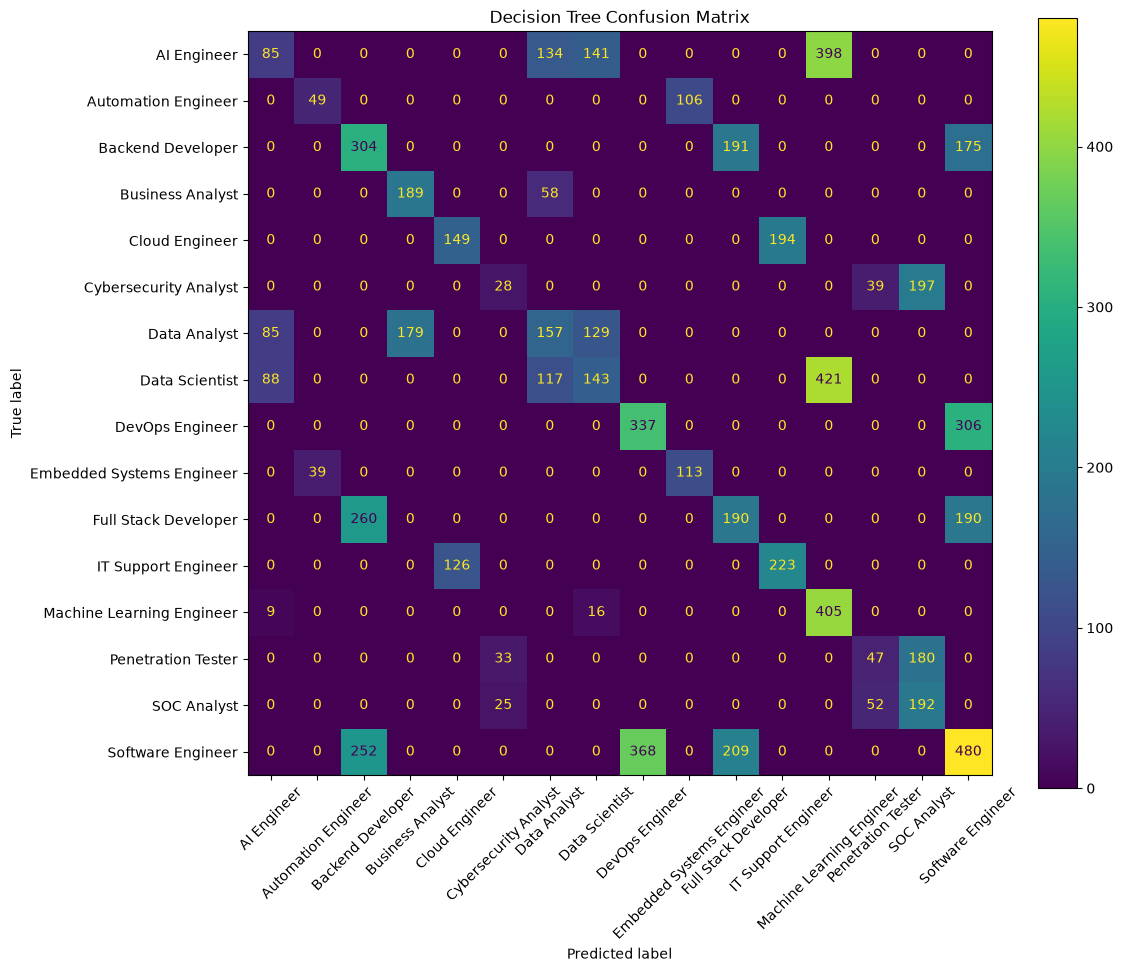

In [32]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=decision_tree.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Decision Tree Confusion Matrix")
plt.show()

In [33]:
random_forest = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [34]:
random_forest.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](16,)","['AI Engineer','Automation Engineer','Backend Developer',..., 'Penetration Tester','SOC Analyst','Software Engineer']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Age','Gender','University_Year',...,'English_Proficiency', 'Interview_Score','Employability_Score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransform

In [35]:
y_pred_rf = random_forest.predict(X_test)

In [36]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.39702868852459017


In [37]:
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

                           precision    recall  f1-score   support

              AI Engineer       0.32      0.35      0.34       758
      Automation Engineer       0.49      0.50      0.50       155
        Backend Developer       0.35      0.38      0.37       670
         Business Analyst       0.54      0.61      0.57       247
           Cloud Engineer       0.52      0.49      0.50       343
    Cybersecurity Analyst       0.37      0.37      0.37       264
             Data Analyst       0.41      0.35      0.38       550
           Data Scientist       0.33      0.34      0.33       769
          DevOps Engineer       0.48      0.45      0.47       643
Embedded Systems Engineer       0.48      0.48      0.48       152
     Full Stack Developer       0.33      0.30      0.31       640
      IT Support Engineer       0.52      0.55      0.54       349
Machine Learning Engineer       0.34      0.32      0.33       430
       Penetration Tester       0.33      0.30      0.31     

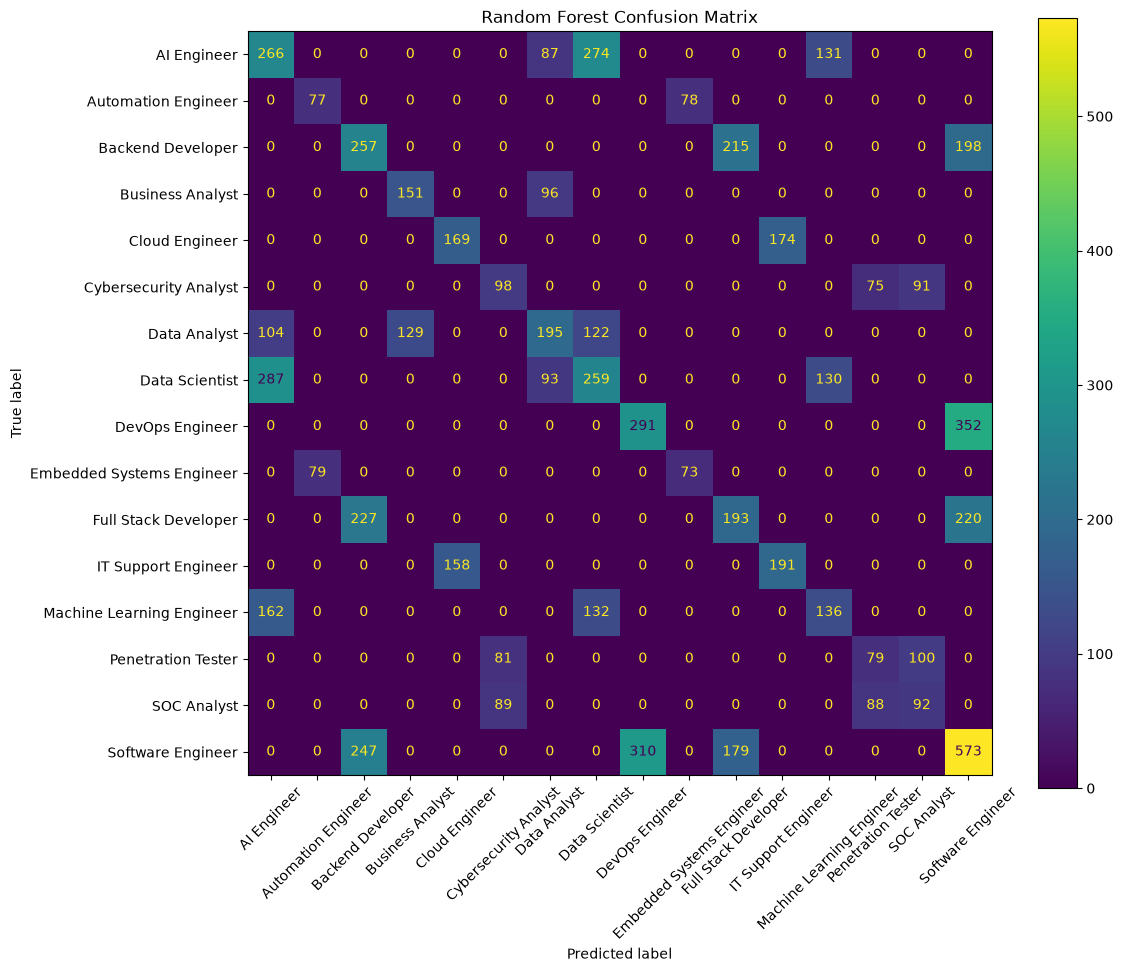

In [38]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=random_forest.classes_
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45
)

plt.title("Random Forest Confusion Matrix")
plt.show()

In [39]:
comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        dt_accuracy,
        rf_accuracy
    ]
})

comparison

,Model,Accuracy
0,Decision Tree,0.395876
1,Random Forest,0.397029


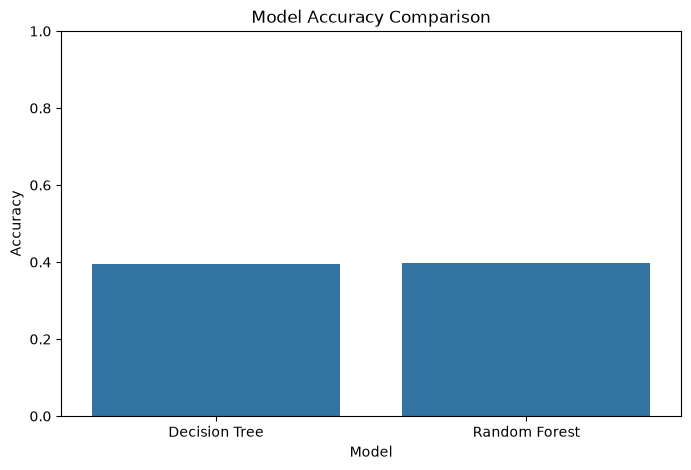

In [40]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.show()

In [41]:
dt_cv = cross_val_score(
    decision_tree,
    X,
    y,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [42]:
print("Decision Tree CV Scores:")
print(dt_cv)

print("Mean CV Accuracy:", dt_cv.mean())

Decision Tree CV Scores:
[0.39100922 0.39216189 0.38742316 0.39177766 0.38204406]
Mean CV Accuracy: 0.3888831967213115


In [43]:
rf_cv = cross_val_score(
    random_forest,
    X,
    y,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

In [44]:
print("Random Forest CV Scores:")
print(rf_cv)

print("Mean CV Accuracy:", rf_cv.mean())

Random Forest CV Scores:
[0.39741291 0.39177766 0.38358094 0.39228996 0.38204406]
Mean CV Accuracy: 0.38942110655737705


In [45]:
cv_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV Accuracy": [
        dt_cv.mean(),
        rf_cv.mean()
    ]
})

cv_comparison

,Model,Mean CV Accuracy
0,Decision Tree,0.388883
1,Random Forest,0.389421


In [46]:
best_model = random_forest

In [47]:
print("Selected Model: Random Forest Classifier")

Selected Model: Random Forest Classifier


In [48]:
preprocessor_fitted = best_model.named_steps[
    "preprocessor"
]

In [49]:
model_fitted = best_model.named_steps[
    "model"
]

In [50]:
feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

In [51]:
importances = model_fitted.feature_importances_

In [52]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

In [53]:
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

In [54]:
feature_importance_df.head(15)

,Feature,Importance
14,num__Employability_Score,0.061905
29,cat__Major_Software Engineering,0.059989
24,cat__Major_Computer Science,0.059491
3,num__CGPA,0.057622
1,num__Attendance_Percentage,0.052953
13,num__Interview_Score,0.052762
2,num__Study_Hours_Per_Week,0.052098
22,cat__Major_Artificial Intelligence,0.044762
28,cat__Major_Information Technology,0.041128
0,num__Age,0.037347


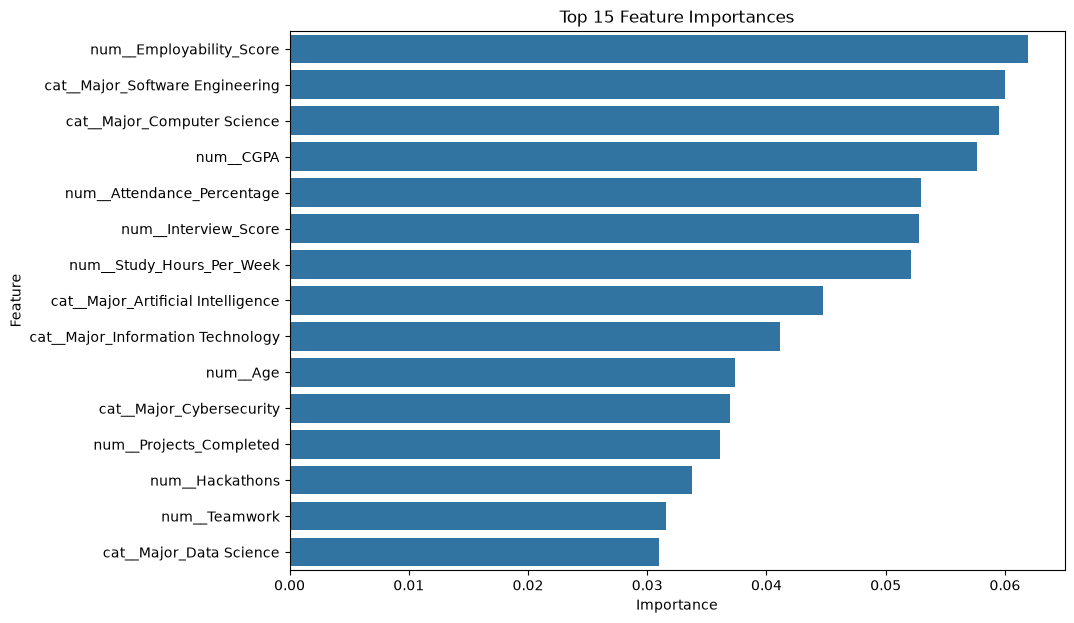

In [55]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.show()

In [56]:
probabilities = best_model.predict_proba(X_test)

In [57]:
probabilities.shape

(7808, 16)

In [58]:
classes = best_model.classes_

print(classes)

['AI Engineer' 'Automation Engineer' 'Backend Developer'
 'Business Analyst' 'Cloud Engineer' 'Cybersecurity Analyst'
 'Data Analyst' 'Data Scientist' 'DevOps Engineer'
 'Embedded Systems Engineer' 'Full Stack Developer' 'IT Support Engineer'
 'Machine Learning Engineer' 'Penetration Tester' 'SOC Analyst'
 'Software Engineer']


In [59]:
print(probabilities[0])

[0.    0.    0.38  0.    0.005 0.    0.005 0.005 0.    0.01  0.335 0.
 0.    0.    0.    0.26 ]


In [60]:
import os

os.makedirs("../models", exist_ok=True)

In [61]:
joblib.dump(
    best_model,
    "../models/career_model.pkl"
)

['../models/career_model.pkl']

In [62]:
loaded_model = joblib.load(
    "../models/career_model.pkl"
)

In [63]:
test_prediction = loaded_model.predict(
    X_test.iloc[:1]
)

print("Predicted Career:", test_prediction[0])

Predicted Career: Backend Developer


In [64]:
sample_student = X_test.iloc[[0]]

In [65]:
career_prediction = loaded_model.predict(
    sample_student
)

print(
    "Recommended Career:",
    career_prediction[0]
)

Recommended Career: Backend Developer


In [66]:
career_probabilities = loaded_model.predict_proba(
    sample_student
)[0]

In [67]:
prediction_table = pd.DataFrame({
    "Career": loaded_model.classes_,
    "Probability": career_probabilities
})

prediction_table = prediction_table.sort_values(
    by="Probability",
    ascending=False
)

prediction_table

,Career,Probability
2,Backend Developer,0.380
10,Full Stack Developer,0.335
15,Software Engineer,0.260
9,Embedded Systems Engineer,0.010
6,Data Analyst,0.005
7,Data Scientist,0.005
4,Cloud Engineer,0.005
3,Business Analyst,0.000
5,Cybersecurity Analyst,0.000
0,AI Engineer,0.000


In [68]:
prediction_table.head(5)

,Career,Probability
2,Backend Developer,0.380
10,Full Stack Developer,0.335
15,Software Engineer,0.260
9,Embedded Systems Engineer,0.010
6,Data Analyst,0.005
